<a href="https://colab.research.google.com/github/jimmynewland/moria/blob/main/Euclid_AGN_FITS_Viewer_and_Sersic_plots.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import sys
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from scipy.special import gamma

from io import BytesIO
from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.visualization import (ImageNormalize, LinearStretch, AsinhStretch, PercentileInterval, ZScaleInterval,)
from astropy import constants as const
from astropy.table import QTable
from astropy.utils.data import download_file

In [ ]:
!pip install astroquery pyvo jupyter_firefly_extensions

from firefly_client import FireflyClient
import pyvo
from astroquery.skyview import SkyView

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 40.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 36.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [jupyter_firefly_extensions]


In [ ]:
FITS_BASE_URL = "https://thinkingwithcode.com/nitarp/agn/fits"
df = pd.read_csv("https://thinkingwithcode.com/nitarp/agn/agn_R90_sersic_profiles_exemplars.csv")

df["Euclid"] = df["Euclid"].astype(str)

In [ ]:
def download_fits_data(url, return_header=False):
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    with fits.open(BytesIO(response.content)) as hdul:
        for hdu in hdul:
            if hdu.data is not None:
                data = np.array(hdu.data, dtype=float)
                if return_header:
                    return data, hdu.header
                return data
    raise ValueError("No image data found in this FITS file")

def get_norm(data, stretch="asinh"):
    interval = PercentileInterval(99.5)
    vmin, vmax = interval.get_limits(data)
    stretch_obj = AsinhStretch() if stretch == "asinh" else LinearStretch()
    return ImageNormalize(vmin=vmin, vmax=vmax, stretch=stretch_obj)

def plot_fits_image(data, ax, title="", stretch="linear"):
    norm = get_norm(data, stretch)

    ax.imshow(data, origin="lower", cmap="gray_r", norm=norm)

    ax.set_title(title, fontsize=18)

def get_fov_arcsec(header, data_shape):
    """On-sky field of view (x, y), in arcsec, read from a FITS header's WCS."""
    wcs = WCS(header)
    scales_arcsec = proj_plane_pixel_scales(wcs) * 3600.0
    ny, nx = data_shape
    return scales_arcsec[0] * nx, scales_arcsec[1] * ny

In [ ]:
def b_n(n):
    """Ciotti & Bertin (1999) approximation to b_n, valid for n >~ 0.5."""
    n = np.asarray(n, dtype=float)
    return 2.0 * n - 1.0 / 3.0 + 4.0 / (405.0 * n) + 46.0 / (25515.0 * n**2) \
           + 131.0 / (1148175.0 * n**3) - 2194697.0 / (30690717750.0 * n**4)

In [ ]:
def sersic_profile(r, n, re, Ie=1.0):
    n = max(n, 0.3)
    bn = b_n(n)
    return Ie * np.exp(-bn * ((r / re) ** (1.0 / n) - 1.0))

    """Sersic surface brightness profile I(r).

    The Ciotti & Bertin b_n approximation is only accurate for n >~ 0.36; below
    that it can blow up, so we floor n at 0.3 for numerical stability. This only
    affects the shape of near-n=0 profiles slightly and does not change the
    0 <= n <= 5 selection criterion applied to the catalog.
    https://arxiv.org/pdf/astro-ph/9911078
    """

In [ ]:
#  https://ned.ipac.caltech.edu/level5/March05/Graham/Graham2.html
def magnitude_profile(r, n, re, Ie=1.0):
    n = max(n, 0.3)
    bn = b_n(n)
    return 20 - 5 * np.log10(re) - 2.5 * np.log10(np.pi*n*np.exp(bn)*gamma(2*n)/bn**(2*n))


In [ ]:
n_points = 200
r_max_in_re = 5.0

profiles = []

for index, row in df.iterrows():
    n_val = float(row["sersic_sersic_vis_index"])
    re_val = float(row["sersic_sersic_vis_radius"])
    id_col = "Euclid"
    r = np.linspace(0.0, r_max_in_re * re_val, n_points)
    I = sersic_profile(r, n_val, re_val, Ie=1.0)
    mag = magnitude_profile(r, n_val, re_val, Ie=1.0)
    profiles.append({
        "id": str(row[id_col]),
        "n": n_val,
        "re": re_val,
        "r": r,
        "I": I,
        "mag": mag
    })

In [ ]:
# Calculate radial surface brightness (magnitude) profiles for each object
for p in profiles:
    # Define the radial magnitude profile (surface brightness) relative to a zero point (e.g. 20)
    # We add a small floor to avoid taking log10 of zero or negative numbers
    p["mu"] = 20 - 2.5 * np.log10(np.clip(p["I"], 1e-10, None))

In [ ]:
# Update the individual plot function to show the Magnitude Profile with an inverted y-axis
def plot_fits_and_sersic_mag(object_id_val):
    df['Euclid'] = df['Euclid'].astype(str)
    row = df[df['Euclid'] == object_id_val].iloc[0]
    selected_profile = next((p for p in profiles if p["id"] == object_id_val), None)

    fig, axes = plt.subplots(1, 2, figsize=(18, 6))

    # Left panel: FITS image
    ax_fits = axes[0]
    data, header = download_fits_data(row["url"], return_header=True)
    norm = get_norm(data, stretch=AsinhStretch(a=0.1))
    ax_fits.imshow(data, origin="lower", cmap="gray_r", norm=norm)
    ax_fits.set_title("Euclid VIS", fontsize=18)

    wcs = WCS(header)
    pixscale_arcsec = proj_plane_pixel_scales(wcs)[0] * 3600
    r_pix = 3.0 / pixscale_arcsec
    circ = plt.Circle((data.shape[1] / 2, data.shape[0] / 2), r_pix, edgecolor="red", facecolor="none", lw=1.5)
    ax_fits.add_patch(circ)
    ax_fits.set_xlabel("RA", fontsize=18)
    ax_fits.set_ylabel("Dec", fontsize=18)

    # Right panel: Magnitude Profile
    ax_sersic = axes[1]
    ax_sersic.plot(selected_profile["r"] / selected_profile["re"], selected_profile["mu"], color="crimson", lw=3)
    ax_sersic.invert_yaxis()  # Magnitudes are inverted: lower values are brighter
    ax_sersic.set_xlabel(r"$r / R_e$", fontsize=18)
    ax_sersic.set_ylabel(r"Surface Brightness $\mu(r)$ (mag)", fontsize=18)
    ax_sersic.set_title("Sérsic Magnitude Profile", fontsize=18)
    ax_sersic.grid(True, linestyle="--", alpha=0.5)

    fig.suptitle(f"ObjID: {object_id_val}\t(n={selected_profile['n']:.2f}, $R_e$={selected_profile['re']:.2f})", fontsize=18)
    plt.tight_layout()
    plt.show()

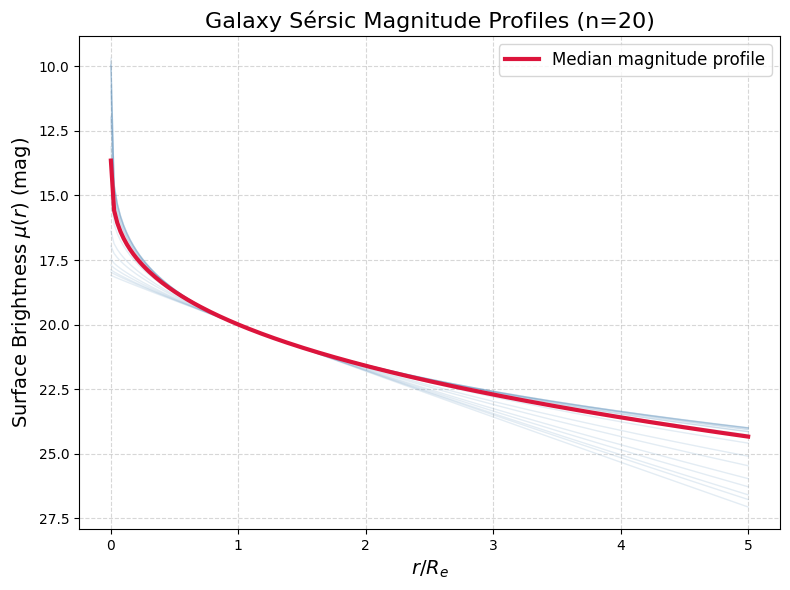

In [ ]:
# Plot the stacked radial magnitude profiles for all galaxies
fig, ax = plt.subplots(figsize=(8, 6))

for p in profiles:
    ax.plot(p["r"] / p["re"], p["mu"], color="steelblue", alpha=0.15, lw=1)

common_x = np.linspace(0, r_max_in_re, n_points)
stack = np.array([np.interp(common_x, p["r"] / p["re"], p["mu"]) for p in profiles])
median_profile = np.median(stack, axis=0)

ax.plot(common_x, median_profile, color="crimson", lw=3, label="Median magnitude profile")
ax.invert_yaxis()  # Invert y-axis because smaller magnitude represents brighter light
ax.set_xlabel(r"$r / R_e$", fontsize=14)
ax.set_ylabel(r"Surface Brightness $\mu(r)$ (mag)", fontsize=14)
ax.set_title(f"Galaxy Sérsic Magnitude Profiles (n={len(profiles)})", fontsize=16)
ax.legend(fontsize=12)
ax.grid(True, linestyle="--", alpha=0.5)
fig.tight_layout()
plt.show()

# Plot FITS Image and Sérsic Profile

In [ ]:
def plot_fits_and_sersic(object_id_val):

    df['Euclid'] = df['Euclid'].astype(str)
    row = df[df['Euclid'] == object_id_val].iloc[0]

    # Find the profile for the specific object_id
    selected_profile = next((p for p in profiles if p["id"] == object_id_val), None)

    fig, axes = plt.subplots(1, 2, figsize=(18, 6))

    ax_fits = axes[0]
    fov_arcsec = None

    data, header = download_fits_data(row["url"], return_header=True)
    norm = get_norm(data, stretch=AsinhStretch(a=0.1))
    ax_fits.imshow(data, origin="lower", cmap="gray_r", norm=norm)

    ax_fits.set_title("Euclid VIS", fontsize=18)

    fov_x, fov_y = get_fov_arcsec(header, data.shape)
    fov_arcsec = max(fov_x, fov_y)

    wcs = WCS(header)
    pixscale_arcsec = proj_plane_pixel_scales(wcs)[0] * 3600
    r_pix = 3.0 / pixscale_arcsec

    circ = plt.Circle(
        (data.shape[1] / 2, data.shape[0] / 2), r_pix,
        edgecolor="red", facecolor="none", lw=1.5
    )
    ax_fits.add_patch(circ)
    ax_fits.set_xlabel("RA", fontsize=18)
    ax_fits.set_ylabel("Dec", fontsize=18)

    # Plot Sersic magnitude profile using 'mu' instead of intensity 'I'
    ax_sersic = axes[1]
    ax_sersic.plot(selected_profile["r"] / selected_profile["re"], selected_profile["mu"], color="crimson", lw=2)
    ax_sersic.invert_yaxis()  # Magnitudes are inverted: smaller is brighter
    ax_sersic.set_xlabel(r"$r / R_e$", fontsize=18)
    ax_sersic.set_title("Sérsic Magnitude Profile", fontsize=18)
    ax_sersic.set_ylabel(r"Surface Brightness $\mu(r)$ (mag)", fontsize=18)
    ax_sersic.grid(True, linestyle="--", alpha=0.5)

    fig.suptitle(f"ObjID: {object_id_val}\t(n={selected_profile['n']:.2f}, $R_e$={selected_profile['re']:.2f})",
                fontsize=18)

    plt.tight_layout()
    plt.show()

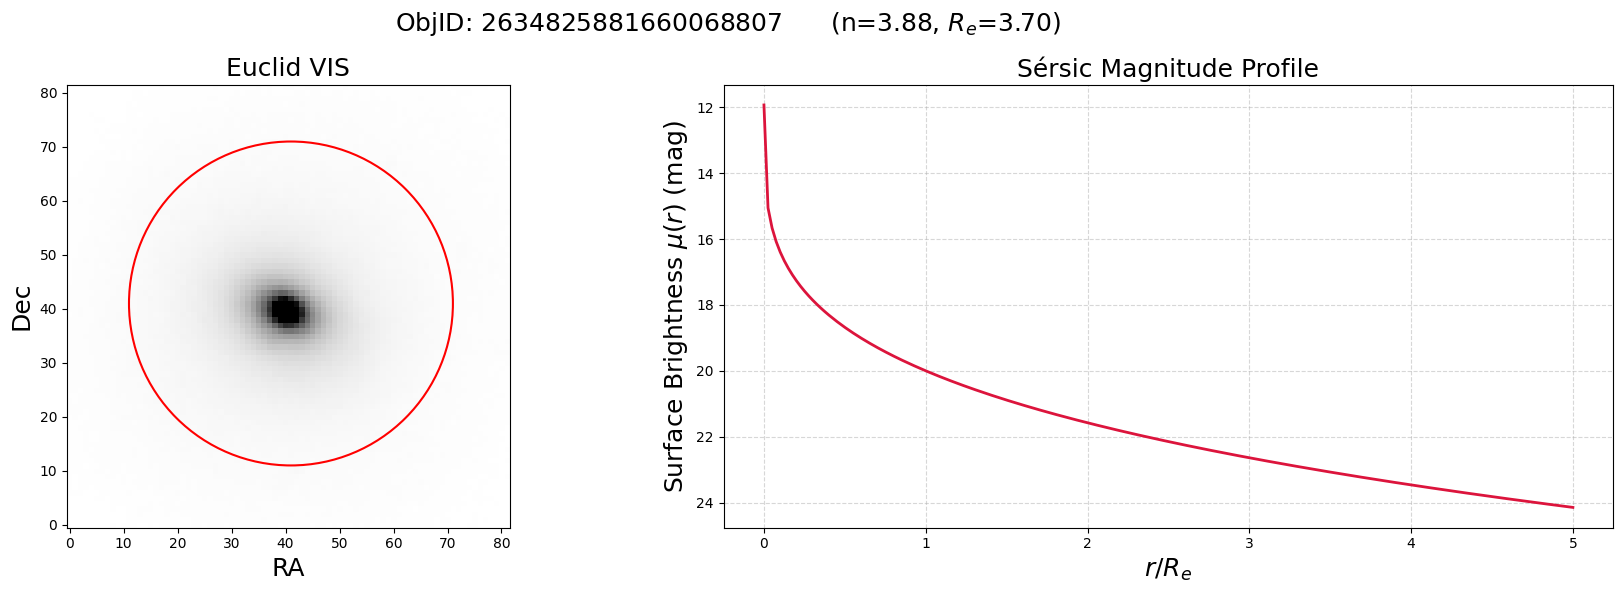

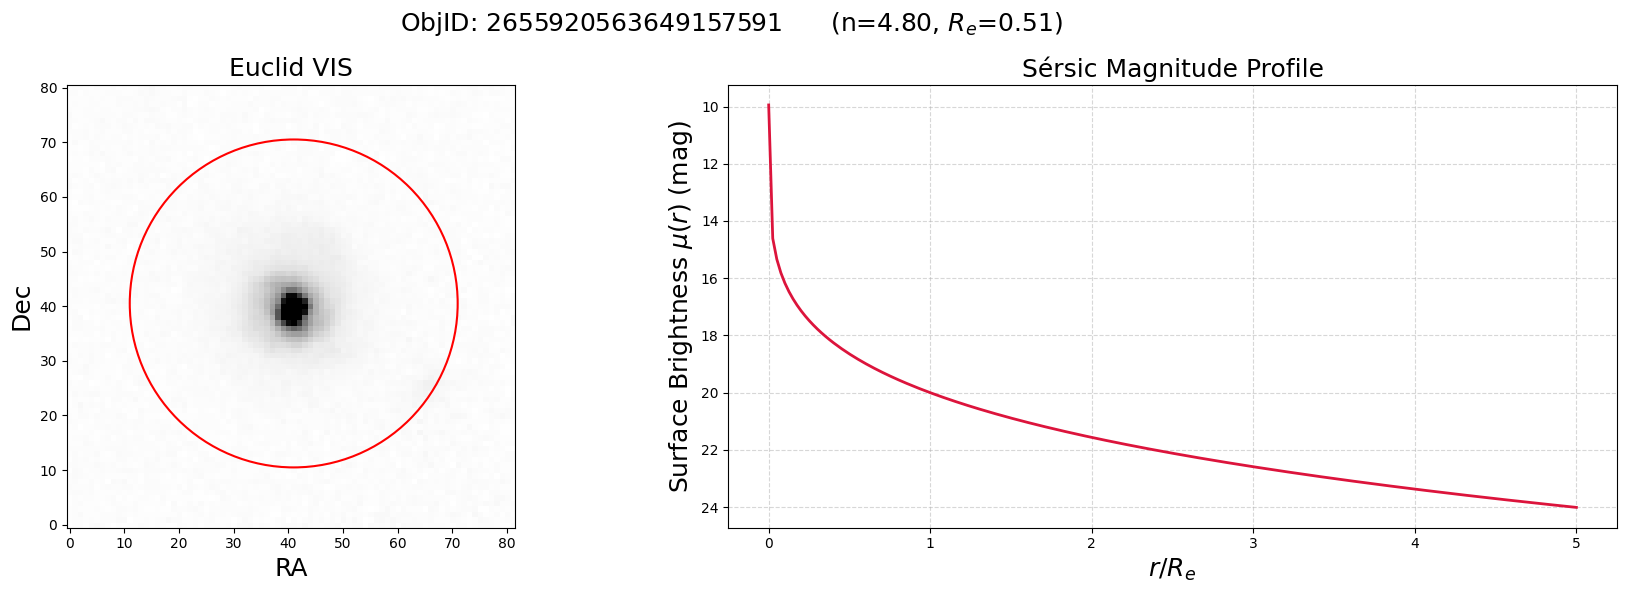

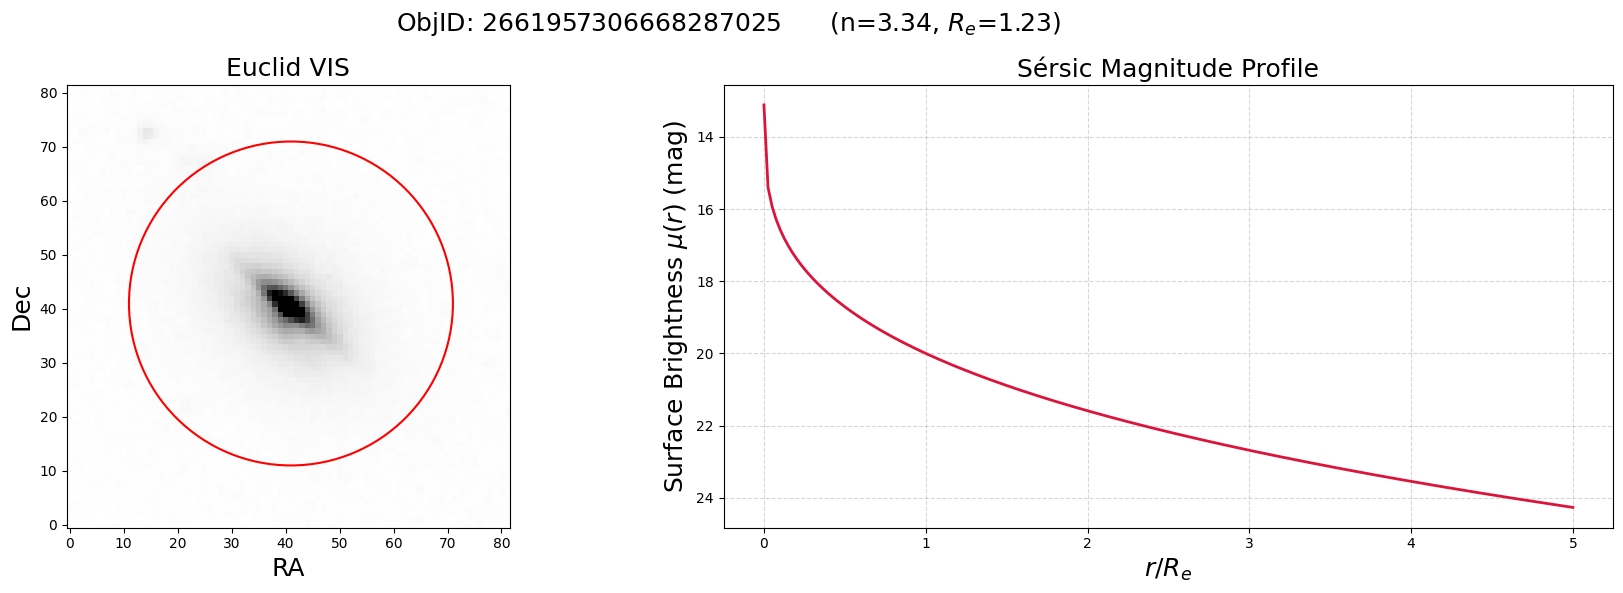

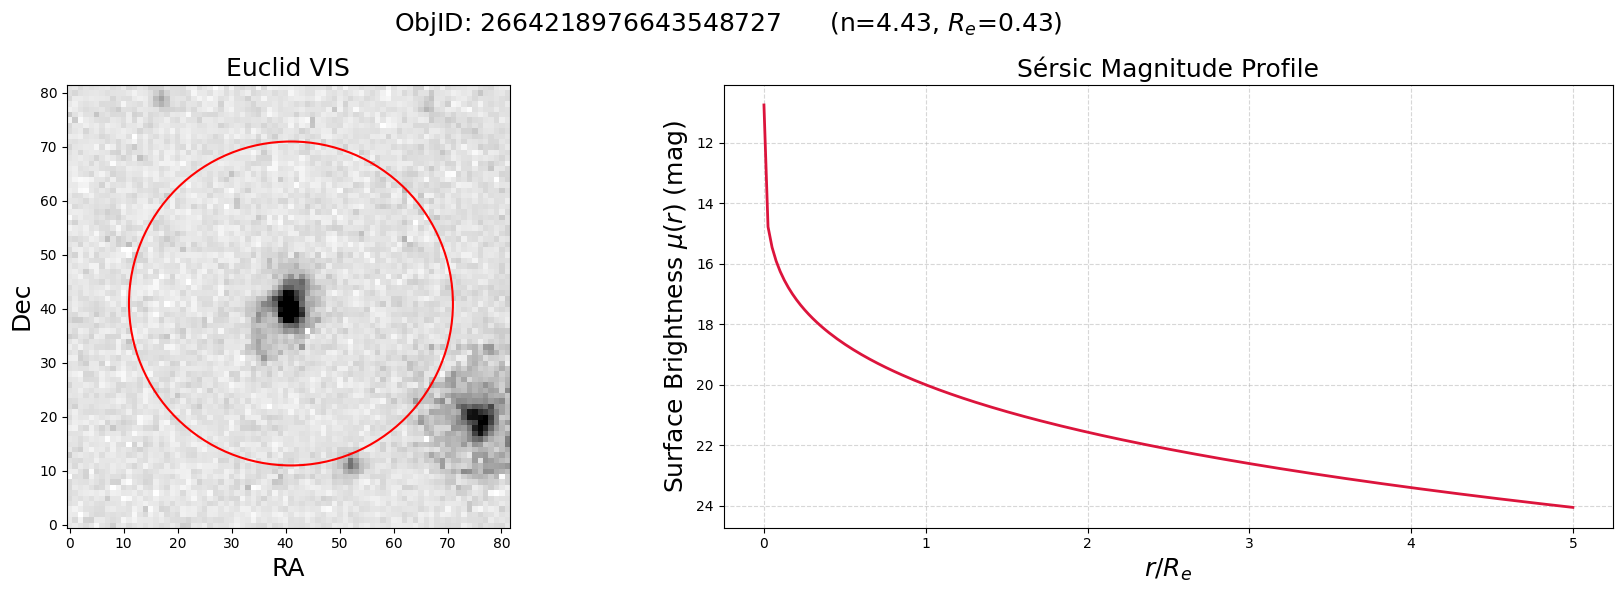

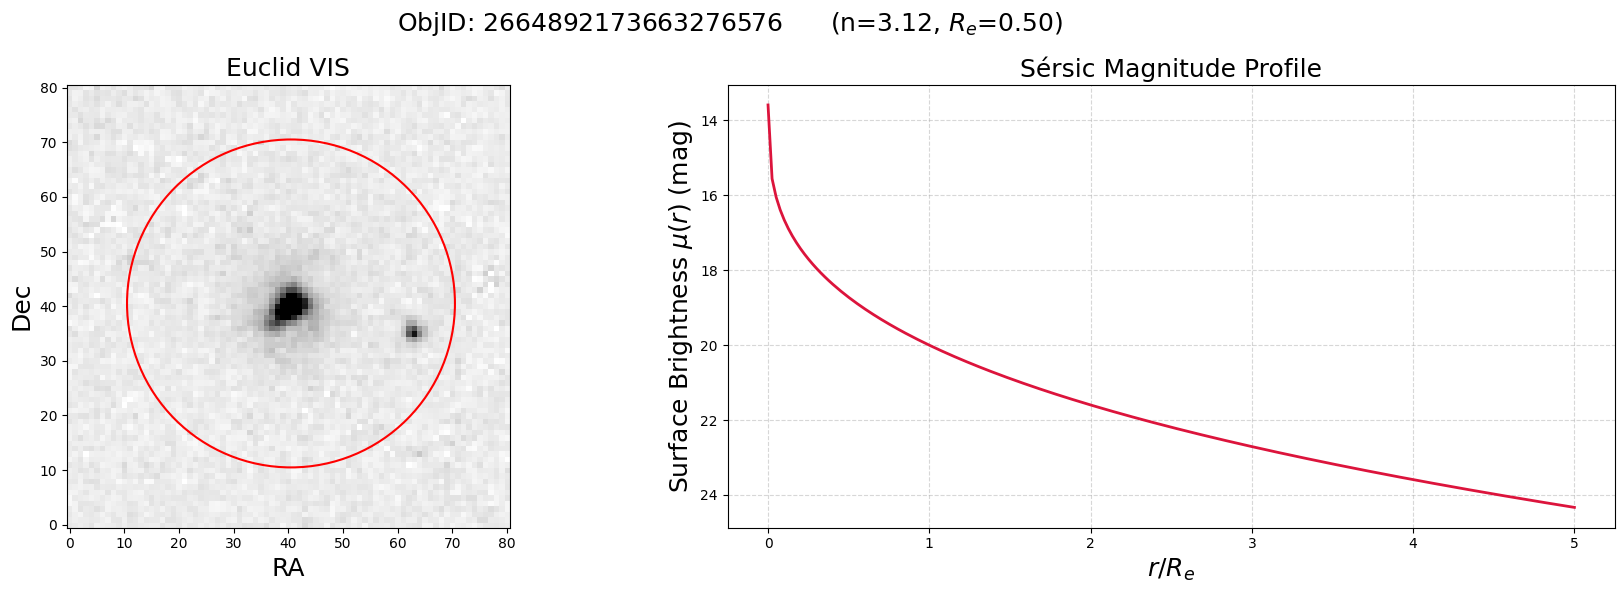

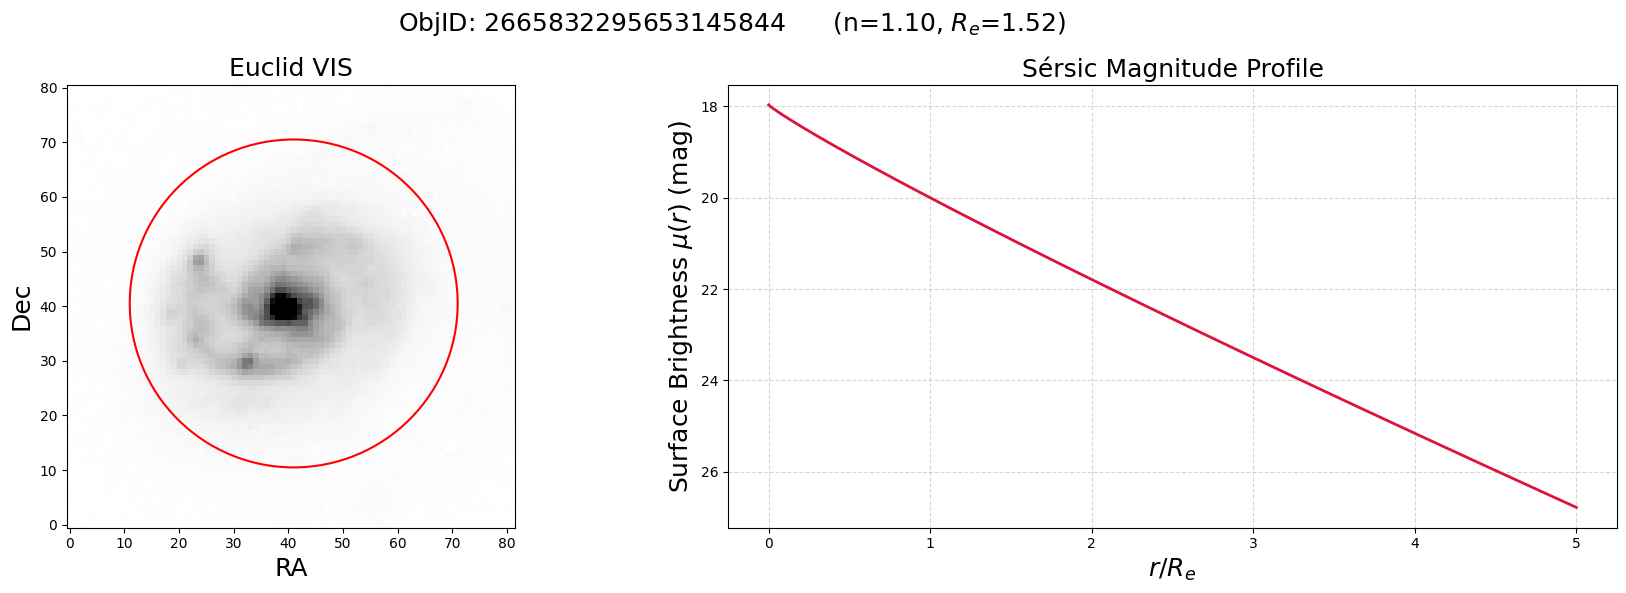

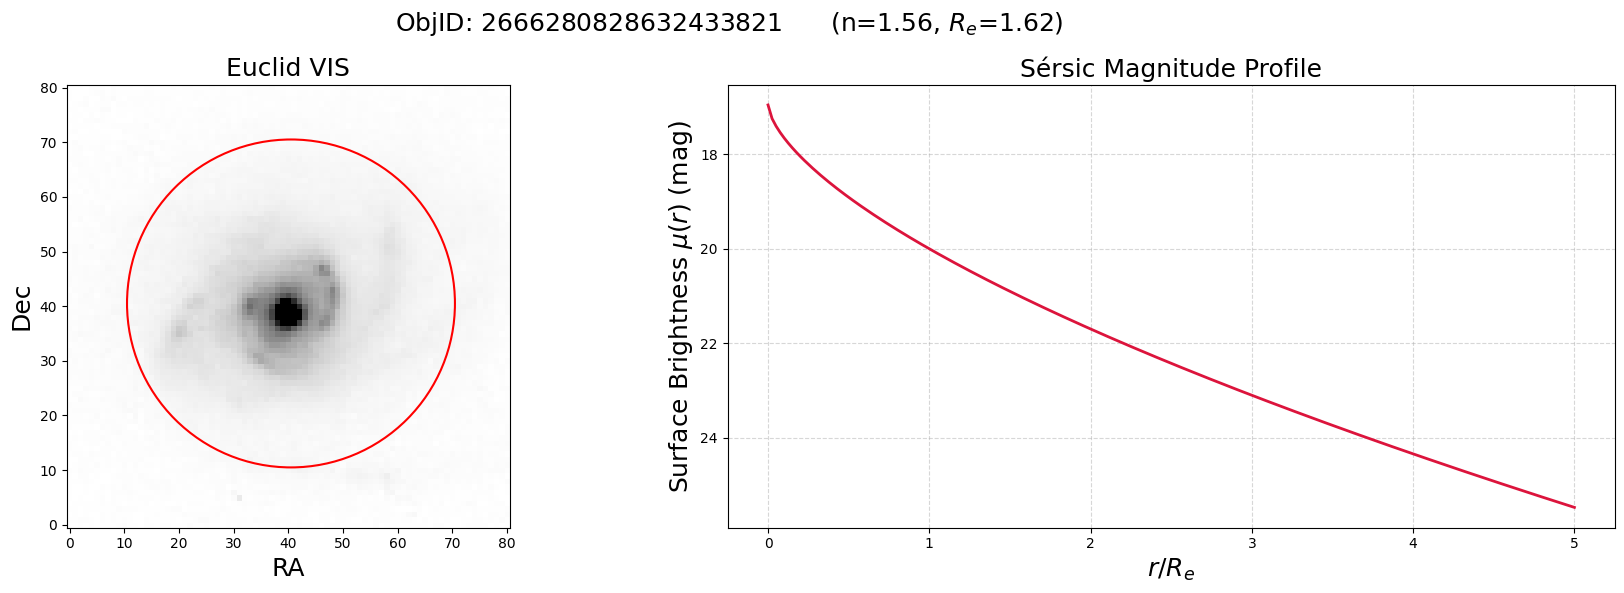

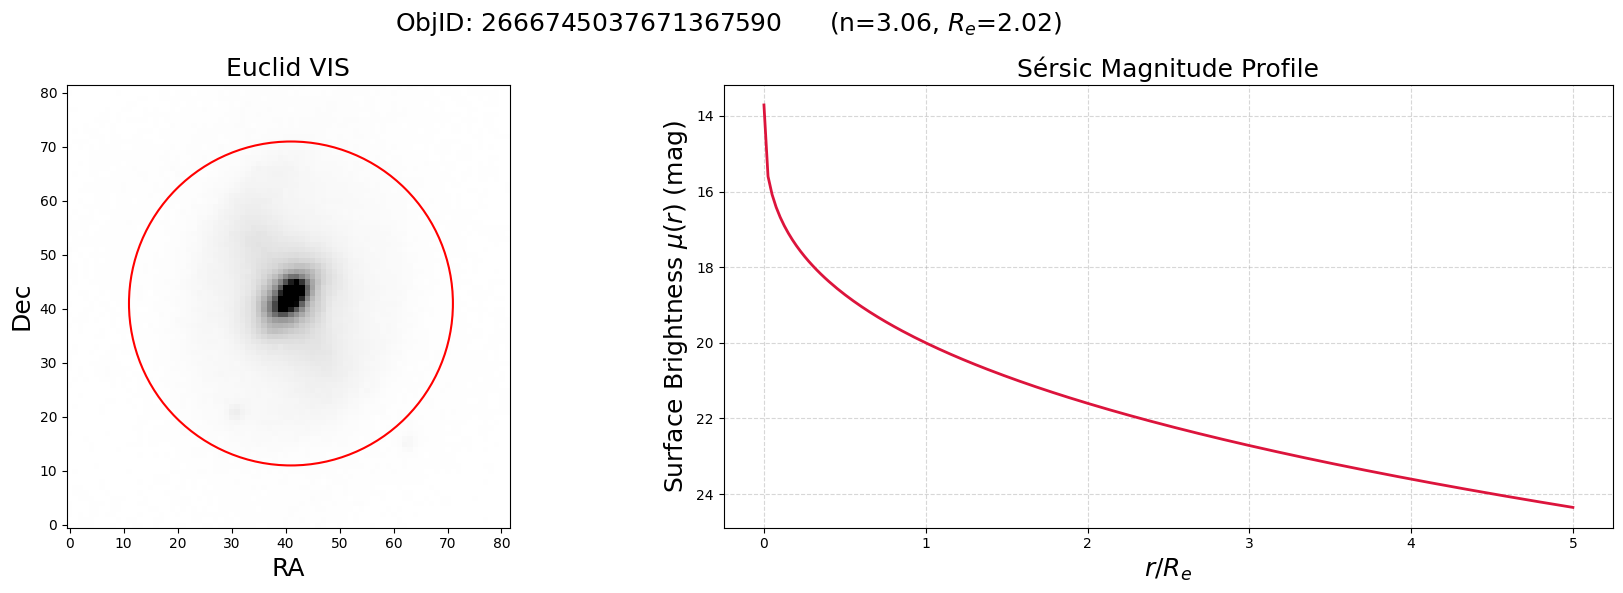

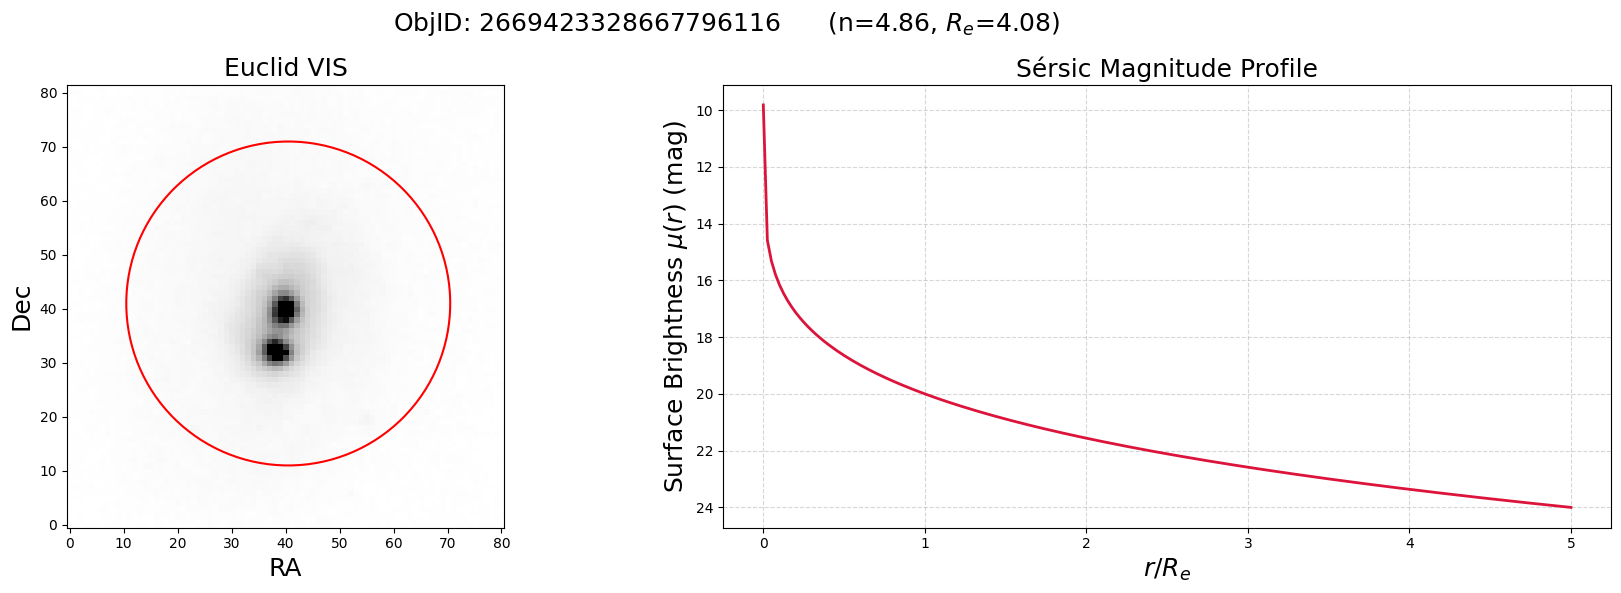

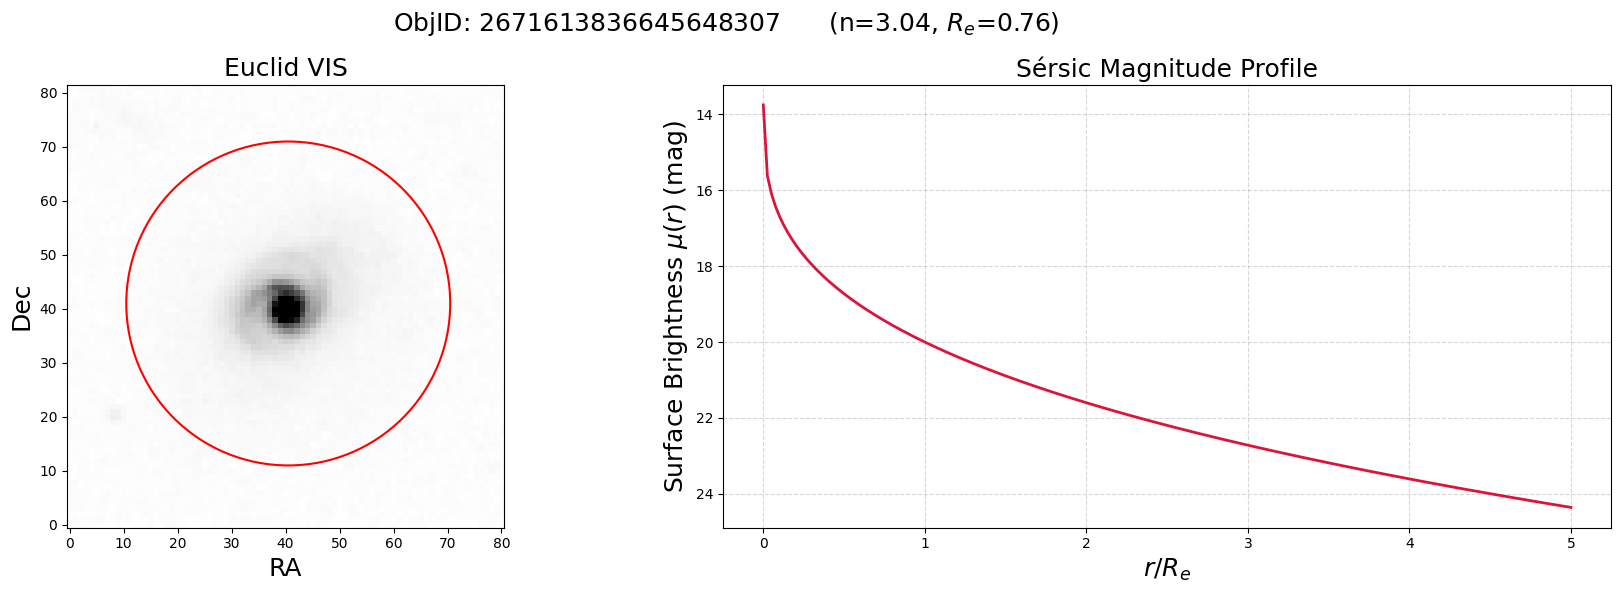

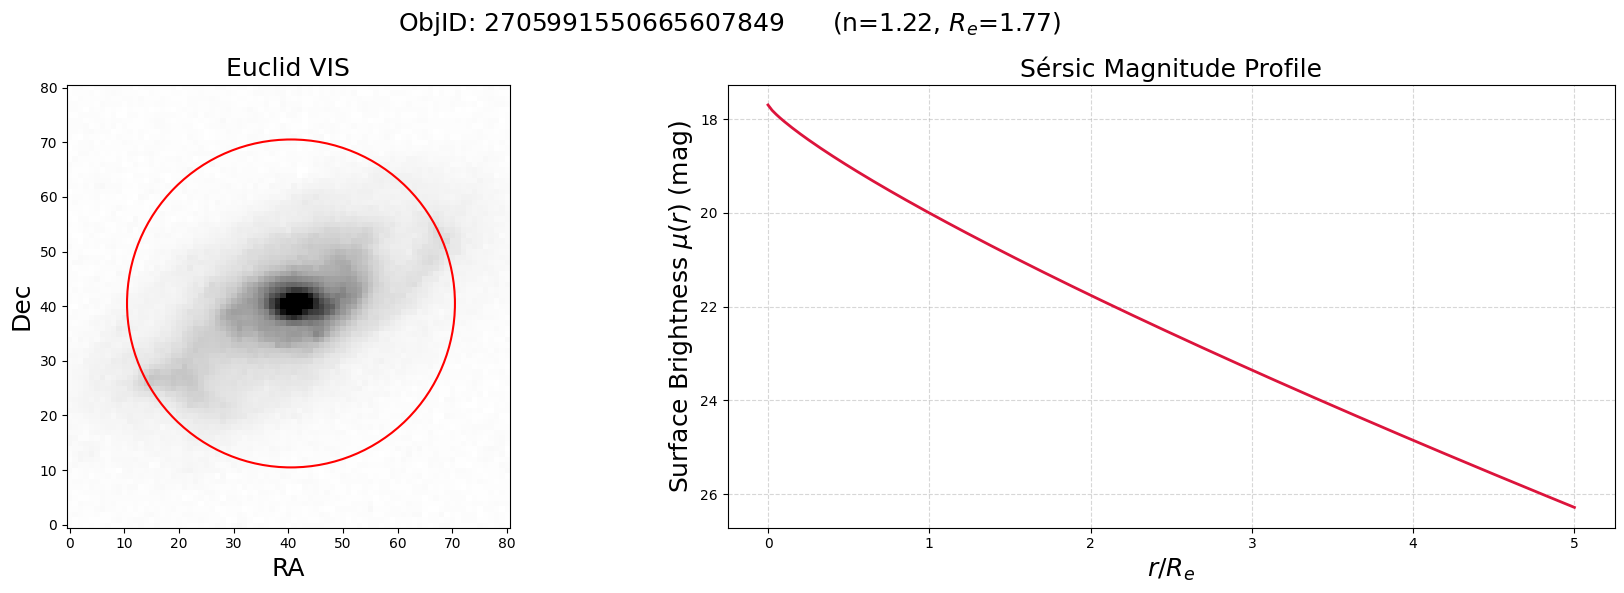

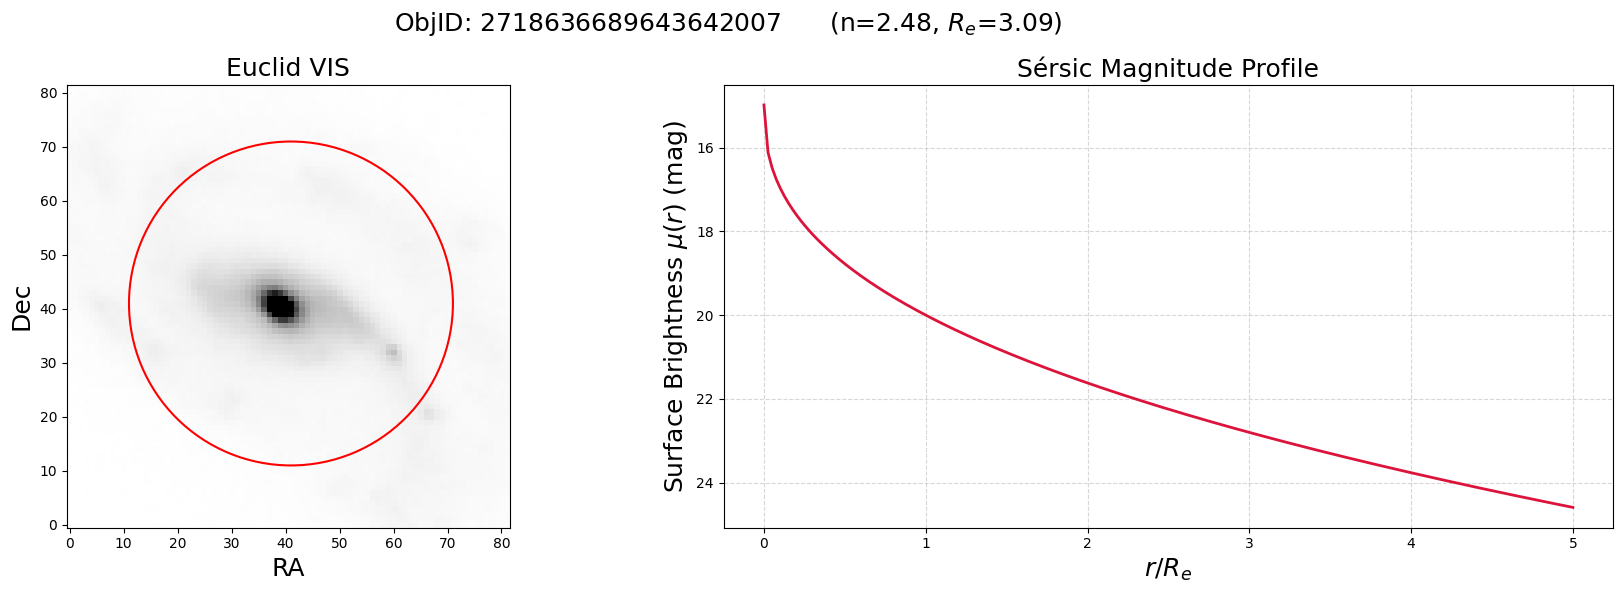

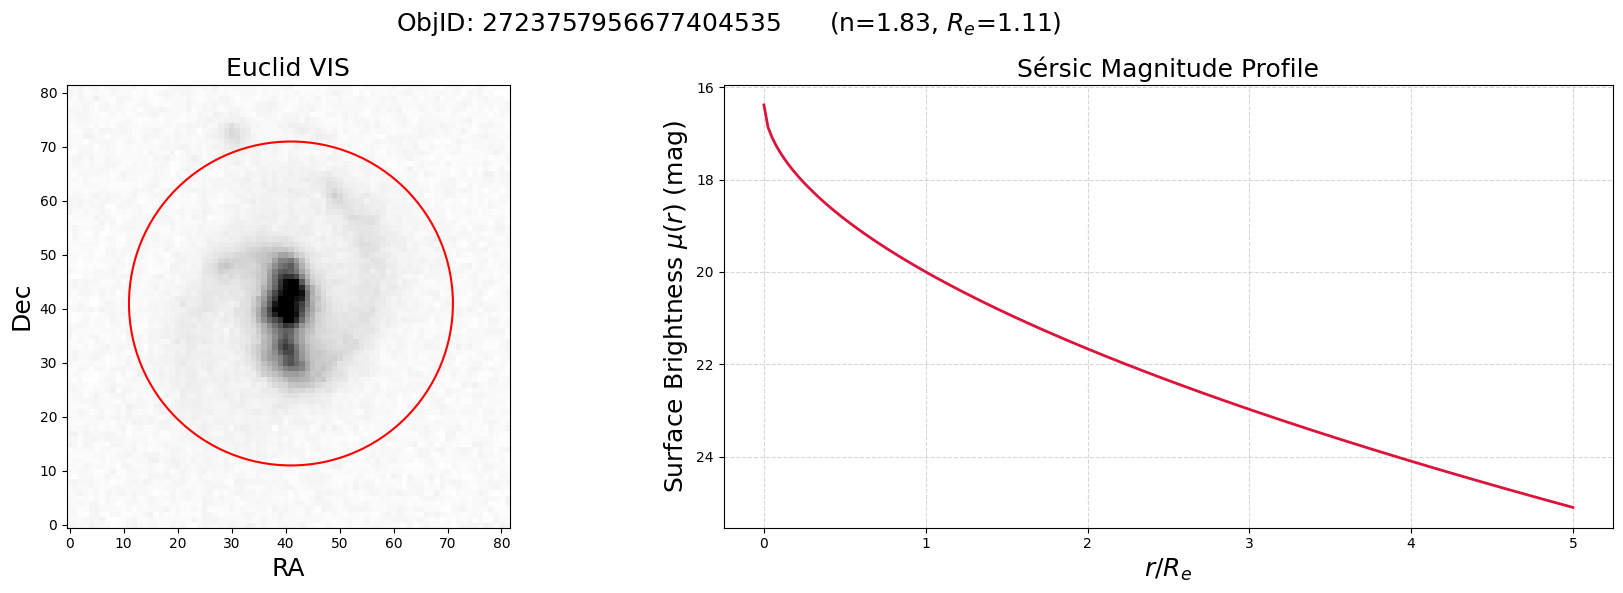

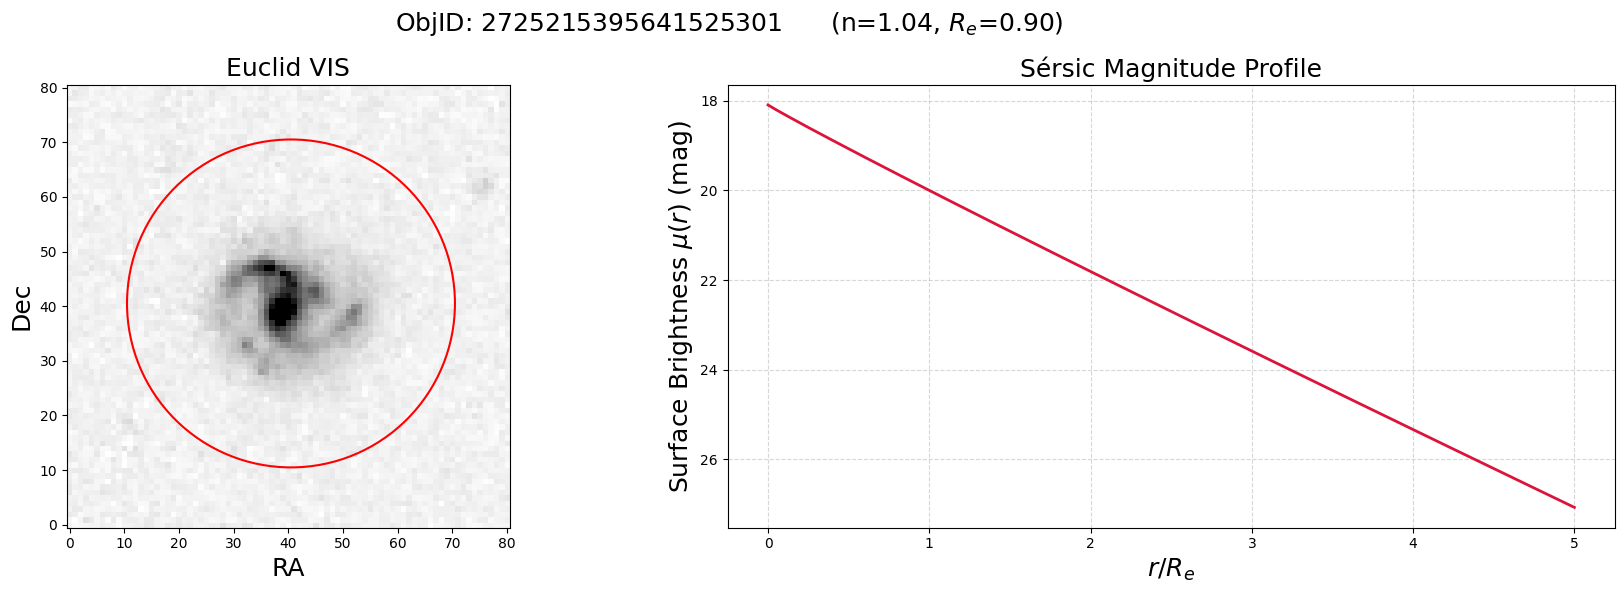

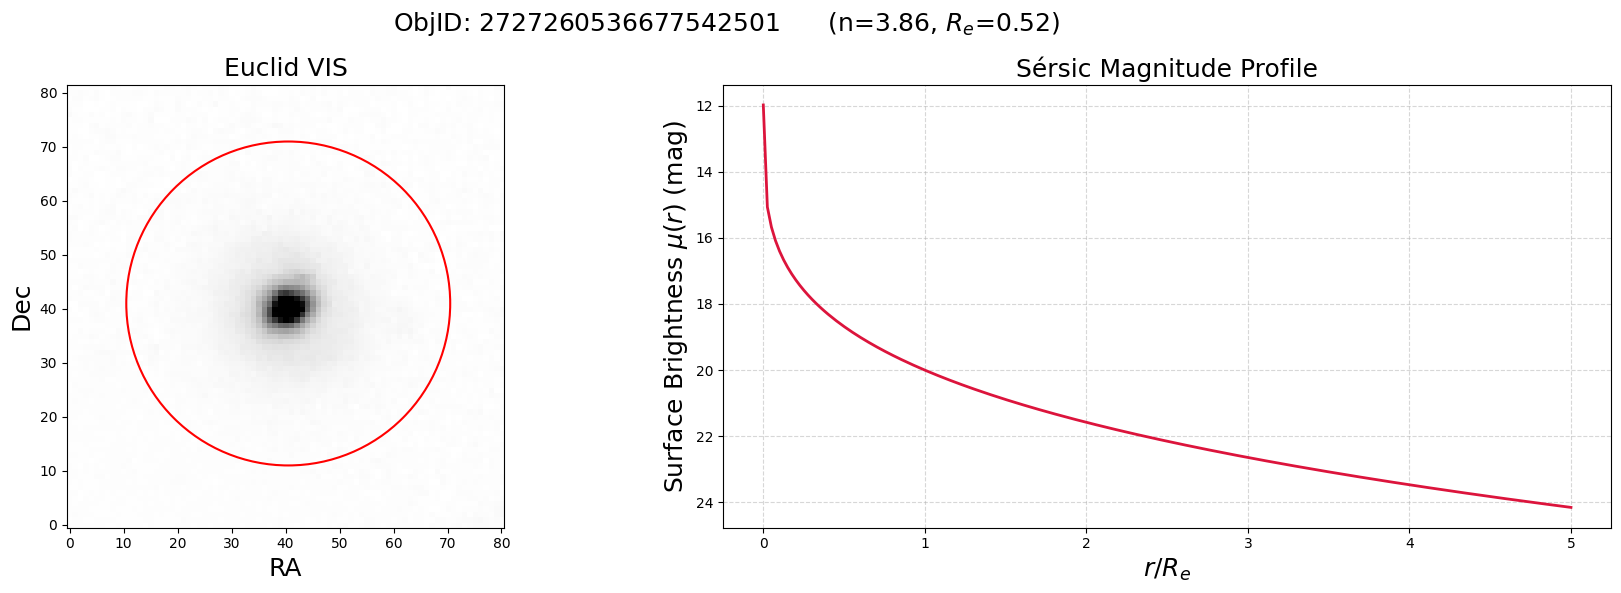

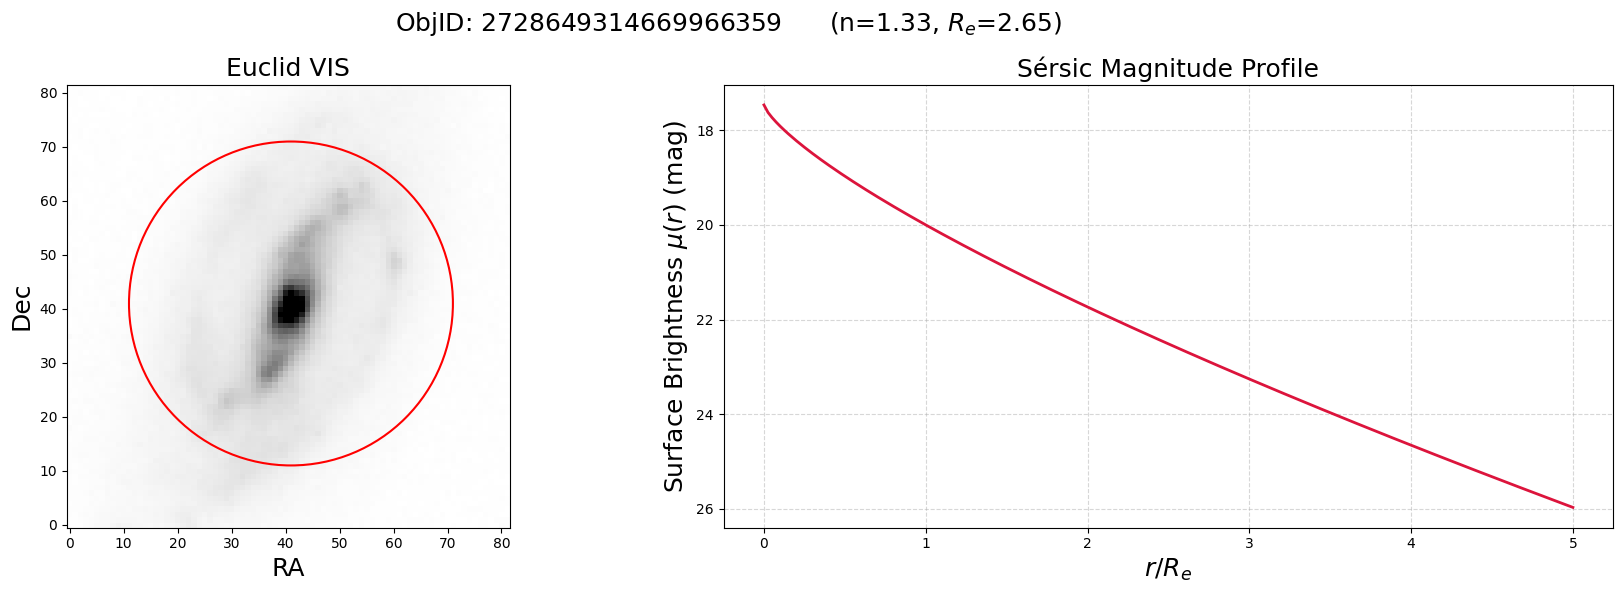

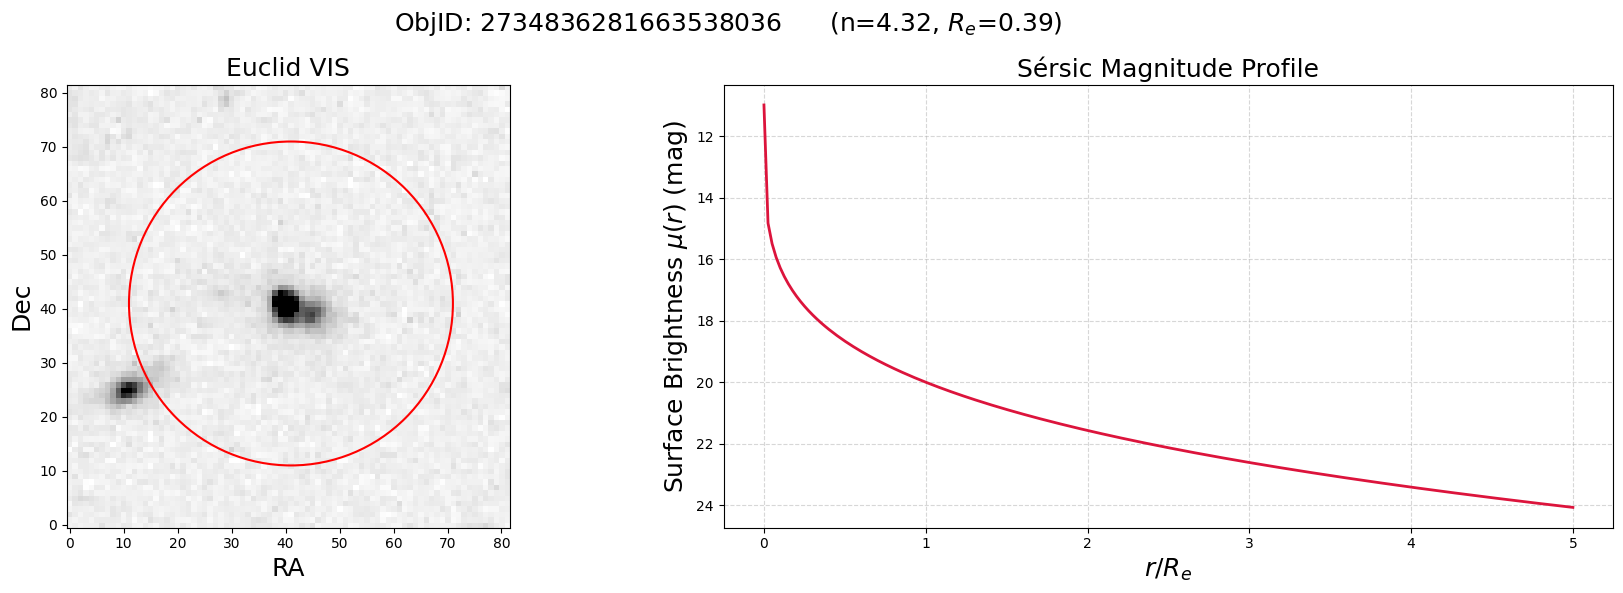

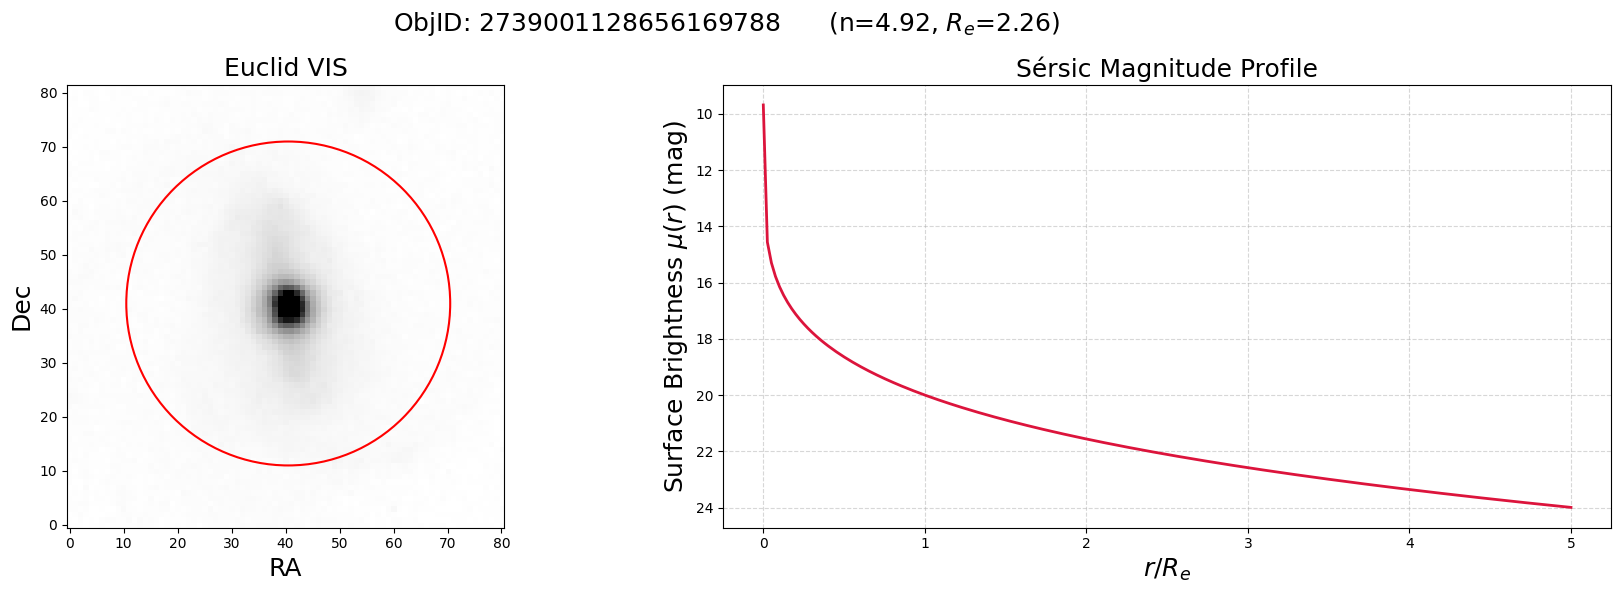

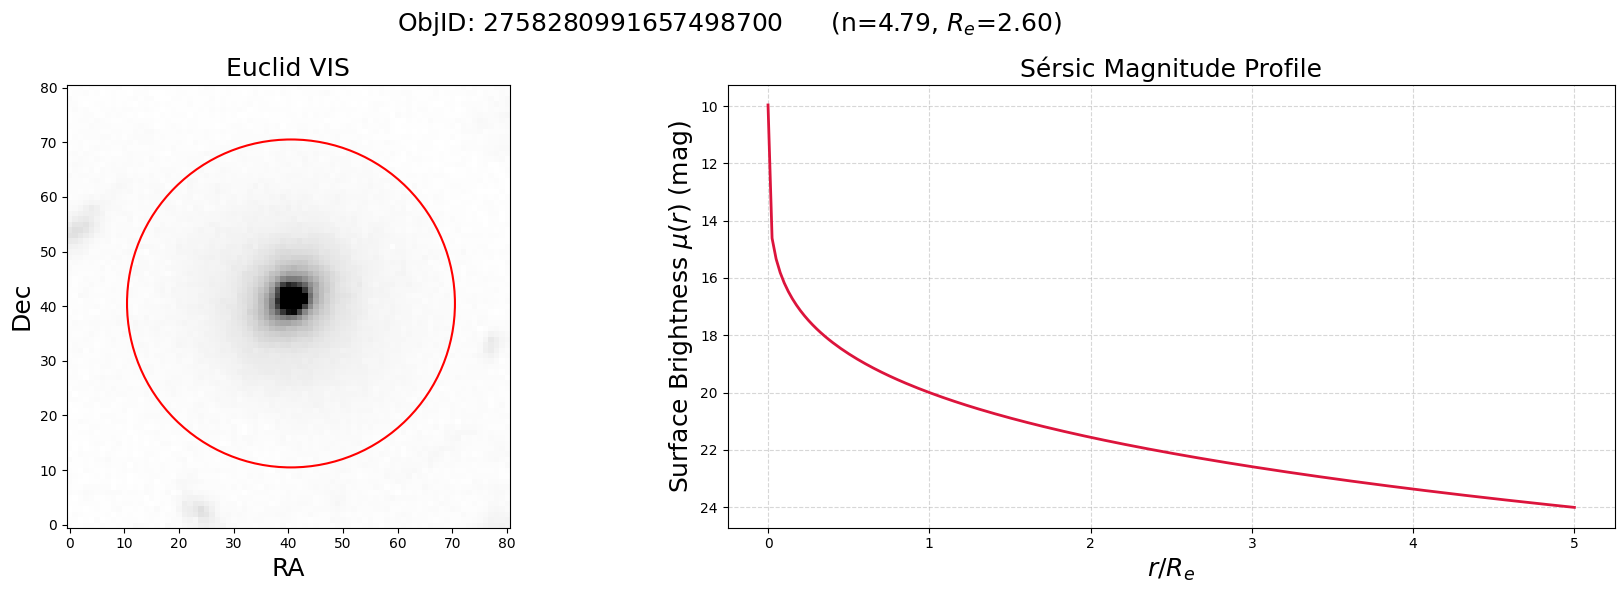

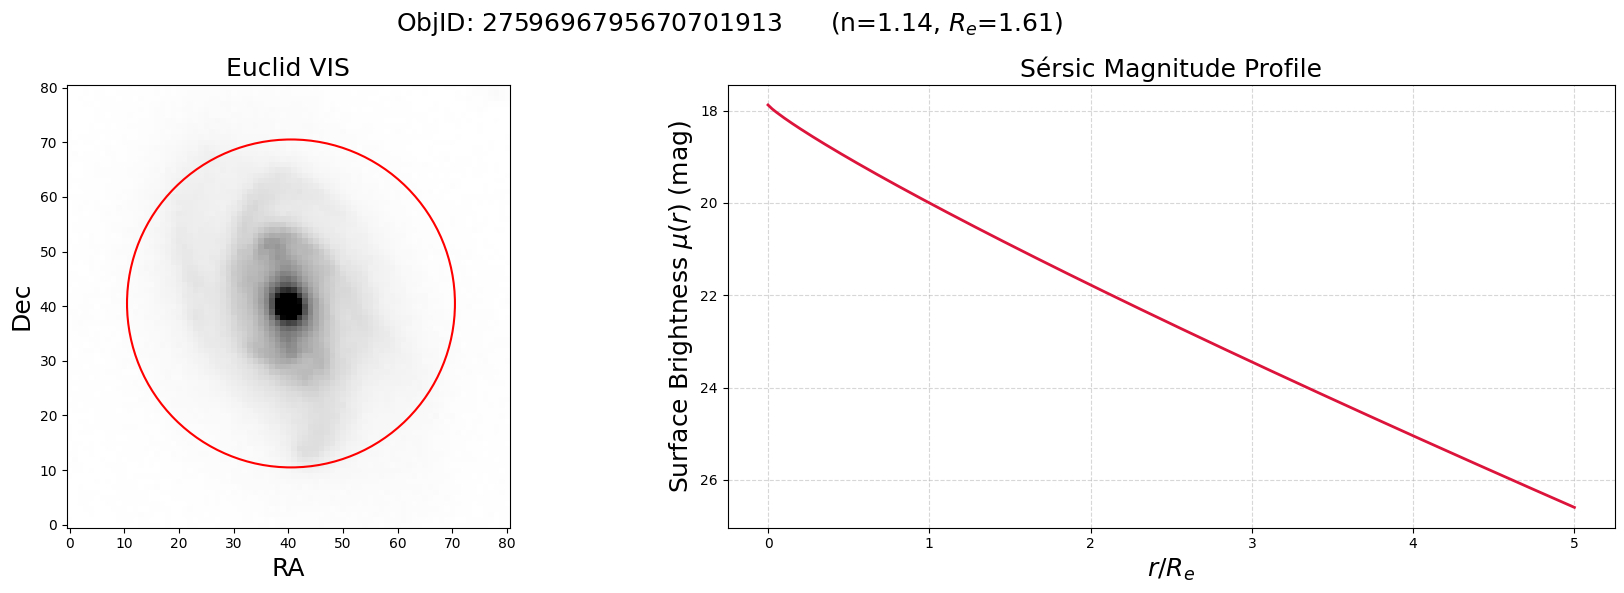

In [ ]:
# We can fix the plot function cell (a029f2f1) or temporarily bypass the issue here by using the intensity profile "I" which has 200 points:
for id in df["Euclid"]:
  plot_fits_and_sersic(str(id))

In [ ]:
# https://colab.research.google.com/github/lonestarchaser/SED/blob/main/Making_SEDS_with_Firefly.ipynb#scrollTo=0ec36a8f-b8b0-411e-ba4f-8ccbcd75e971
fc = FireflyClient.make_client(url="https://irsa.ipac.caltech.edu/irsaviewer")

from IPython.display import display, HTML

# URL you want to open
firefly_url =  fc.get_firefly_url()

# HTML and JavaScript to open a new tab
html_code = f'''
<script type="text/javascript">
    window.open("{firefly_url}", "_blank");
</script>
'''

# Display the HTML
display(HTML(html_code))

Open your web browser to https://irsa.ipac.caltech.edu/irsaviewer/?__wsch=MjAyNi0xMS0xMA


In [ ]:
from astropy.coordinates import SkyCoord
from astropy.utils.data import download_file

group = "euclid_group"

for i, (index, row) in enumerate(df.iterrows()):
    target = SkyCoord(ra=row["RAJ2000"], dec=row["DEJ2000"], unit=("deg", "deg"))
    plot_id = f"euclid_vis_{i}"

    # Download once (cached) and upload to Firefly
    local_path = download_file(row["url"], cache=True)
    fc.show_fits_image(
        file_input=fc.upload_file(local_path),
        plot_id=plot_id,
        Title=f"Euclid VIS: {index}",
        plot_group_id=group,   # shared group so they display together
    )

    fc.set_zoom(plot_id=plot_id, factor=4.0)
    fc.set_pan(plot_id=plot_id, x=target.ra.deg, y=target.dec.deg, coord="j2000")

In [ ]:
for index, row in df.iterrows():
  print(row['url'])

https://thinkingwithcode.com/nitarp/agn/fits/2634825881660068807_VIS_cutout.fits
https://thinkingwithcode.com/nitarp/agn/fits/2655920563649157591_VIS_cutout.fits
https://thinkingwithcode.com/nitarp/agn/fits/2661957306668287025_VIS_cutout.fits
https://thinkingwithcode.com/nitarp/agn/fits/2664218976643548727_VIS_cutout.fits
https://thinkingwithcode.com/nitarp/agn/fits/2664892173663276576_VIS_cutout.fits
https://thinkingwithcode.com/nitarp/agn/fits/2665832295653145844_VIS_cutout.fits
https://thinkingwithcode.com/nitarp/agn/fits/2666280828632433821_VIS_cutout.fits
https://thinkingwithcode.com/nitarp/agn/fits/2666745037671367590_VIS_cutout.fits
https://thinkingwithcode.com/nitarp/agn/fits/2669423328667796116_VIS_cutout.fits
https://thinkingwithcode.com/nitarp/agn/fits/2671613836645648307_VIS_cutout.fits
https://thinkingwithcode.com/nitarp/agn/fits/2705991550665607849_VIS_cutout.fits
https://thinkingwithcode.com/nitarp/agn/fits/2718636689643642007_VIS_cutout.fits
https://thinkingwithcode.com